# Лабораторная работа №3
## Параметры командной строки и арифметические выражения

**Вариант 17**

### Задания
1. Программа на ассемблере, которая по введённому символу печатает его ASCII-код. Символ передаётся как параметр командной строки.
2. Программа на ассемблере для вычисления арифметического выражения `(((c-b)-b)/b)`. `a`, `b`, `c` передаются как параметры командной строки.
3. Аналогичная программа на C. Сверка результатов.

---
## Задание 1. ASCII-код символа

### Исходный код (ascii.asm)

```asm
format ELF executable 3
entry start

segment readable executable
start:
    mov ebp, esp
    mov eax, [ebp]
    cmp eax, 2
    jl .usage

    mov esi, [ebp + 8]
    movzx eax, byte [esi]
    test eax, eax
    jz .usage

    call print_num

    mov eax, 4
    mov ebx, 1
    mov ecx, nl
    mov edx, 1
    int 0x80

    mov eax, 1
    xor ebx, ebx
    int 0x80

.usage:
    mov eax, 4
    mov ebx, 1
    mov ecx, usage_msg
    mov edx, usage_len
    int 0x80
    mov eax, 1
    mov ebx, 1
    int 0x80

print_num:
    mov edi, buf + 15
    mov ebx, 10
.cnv:
    xor edx, edx
    div ebx
    add dl, '0'
    mov [edi], dl
    dec edi
    test eax, eax
    jnz .cnv
    inc edi
    mov edx, buf + 15
    sub edx, edi
    inc edx
    mov ecx, edi
    mov eax, 4
    mov ebx, 1
    int 0x80
    ret

segment readable writeable
buf         rb 16
nl          db 0x0A
usage_msg   db 'Usage: ./ascii <char>', 0x0A
usage_len   = $ - usage_msg
```

In [ ]:
!fasm ascii.asm ascii
!chmod +x ascii
!./ascii A
!./ascii a
!./ascii 0

### Результат работы

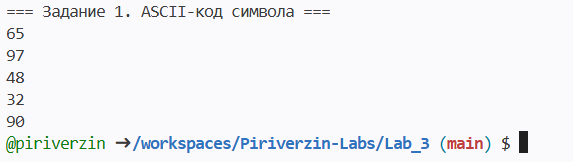



---
## Задание 2. Арифметическое выражение на FASM

**Выражение:** `(((c-b)-b)/b)`

Упрощённо: `(c - 2b) / b`

### Исходный код (calc.asm)

```asm
format ELF executable 3
entry start

segment readable executable
start:
    mov ebp, esp
    mov eax, [ebp]
    cmp eax, 4
    jne .usage

    mov esi, [ebp + 8]
    call parse_int
    mov [var_a], eax

    mov esi, [ebp + 12]
    call parse_int
    mov [var_b], eax

    mov esi, [ebp + 16]
    call parse_int
    mov [var_c], eax

    mov eax, [var_c]
    sub eax, [var_b]
    sub eax, [var_b]
    cdq
    mov ebx, [var_b]
    test ebx, ebx
    jz .div_zero
    idiv ebx

    call print_signed

    mov eax, 4
    mov ebx, 1
    mov ecx, nl
    mov edx, 1
    int 0x80

    mov eax, 1
    xor ebx, ebx
    int 0x80

.usage:
    mov eax, 4
    mov ebx, 1
    mov ecx, usage_msg
    mov edx, usage_len
    int 0x80
    mov eax, 1
    mov ebx, 1
    int 0x80

.div_zero:
    mov eax, 4
    mov ebx, 1
    mov ecx, div_zero_msg
    mov edx, div_zero_len
    int 0x80
    mov eax, 1
    mov ebx, 2
    int 0x80

parse_int:
    xor eax, eax
    xor ecx, ecx
    movzx edx, byte [esi]
    cmp dl, '-'
    jne .loop
    mov ecx, 1
    inc esi
.loop:
    movzx edx, byte [esi]
    test dl, dl
    jz .done
    cmp dl, '0'
    jb .done
    cmp dl, '9'
    ja .done
    imul eax, eax, 10
    sub dl, '0'
    movzx edx, dl
    add eax, edx
    inc esi
    jmp .loop
.done:
    test ecx, ecx
    jz .ret
    neg eax
.ret:
    ret

print_signed:
    test eax, eax
    jns .positive
    push eax
    mov eax, 4
    mov ebx, 1
    mov ecx, minus
    mov edx, 1
    int 0x80
    pop eax
    neg eax
.positive:
    mov edi, buf + 15
    mov ebx, 10
.cnv:
    xor edx, edx
    div ebx
    add dl, '0'
    mov [edi], dl
    dec edi
    test eax, eax
    jnz .cnv
    inc edi
    mov edx, buf + 15
    sub edx, edi
    inc edx
    mov ecx, edi
    mov eax, 4
    mov ebx, 1
    int 0x80
    ret

segment readable writeable
var_a       dd 0
var_b       dd 0
var_c       dd 0
buf         rb 16
nl          db 0x0A
minus       db '-'
usage_msg   db 'Usage: ./calc a b c', 0x0A
usage_len   = $ - usage_msg
div_zero_msg db 'Error: division by zero', 0x0A
div_zero_len = $ - div_zero_msg
```

In [ ]:
!fasm calc.asm calc
!chmod +x calc
!./calc 10 3 20
!./calc 100 7 30
!./calc 0 3 1

### Результат работы

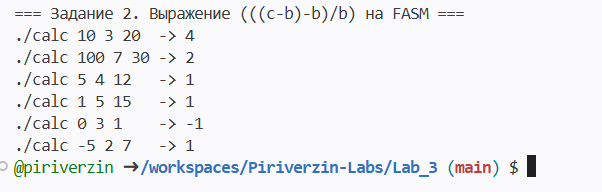


---
## Задание 3. То же на C

### Исходный код (calc.c)

```c
#include <stdio.h>
#include <stdlib.h>

int main(int argc, char *argv[]) {
    if (argc != 4) {
        fprintf(stderr, "Usage: %s a b c\n", argv[0]);
        return 1;
    }
    int a = atoi(argv[1]);
    int b = atoi(argv[2]);
    int c = atoi(argv[3]);
    if (b == 0) {
        fprintf(stderr, "Error: division by zero\n");
        return 2;
    }
    int result = ((c - b) - b) / b;
    printf("%d\n", result);
    return 0;
}
```

In [ ]:
!gcc -Os -s -o calc_c calc.c
!./calc_c 10 3 20
!./calc_c 100 7 30
!./calc_c 0 3 1

### Результат работы

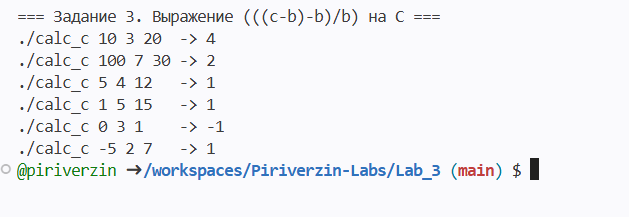

---
## Сверка результатов ASM vs C

In [ ]:
for args in ['10 3 20', '100 7 30', '5 4 12', '1 5 15', '0 3 1', '-5 2 7']:
    asm = !./calc {args}
    c = !./calc_c {args}
    status = 'OK' if asm == c else 'FAIL'
    print(f'{status}  ({args}): ASM={asm[0]}  C={c[0]}')

### Результат

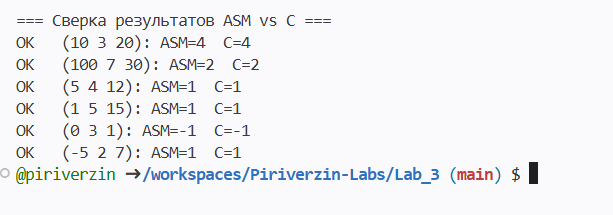

---
## Вывод по лабораторной работе

1. Реализована программа на FASM, которая выводит ASCII-код символа, переданного как параметр командной строки.
2. Реализована программа на FASM, которая вычисляет выражение `(((c-b)-b)/b)` при `a`, `b`, `c`, переданных через командную строку.
3. Реализована аналогичная программа на C. Результаты обеих программ **совпадают** на всех тестовых наборах.
4. Размер ассемблерной версии значительно меньше C-версии (как и в лабораторной №2).